<a href="https://colab.research.google.com/github/AnshuAnshu01/ML/blob/main/simple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv('placement.csv')

In [5]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Text(0, 0.5, 'Package(in lpa)')

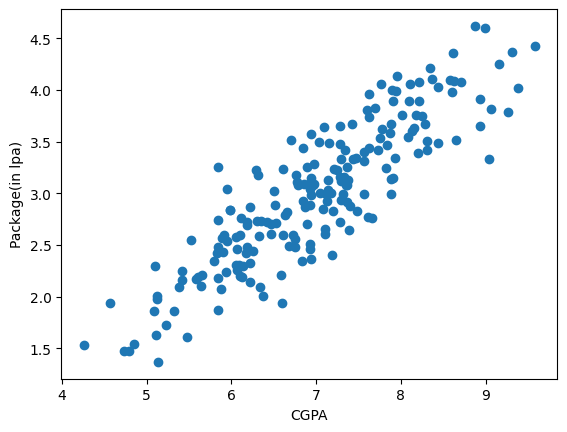

In [6]:
plt.scatter(df['cgpa'],df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [7]:
X = df.iloc[:,0:1]
y = df.iloc[:,-1]

In [8]:
X.head()

,cgpa
0,6.89
1,5.12
2,7.82
3,7.42
4,6.94


In [9]:
y.head()

,package
0,3.26
1,1.98
2,3.25
3,3.67
4,3.57


In [10]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [11]:
from sklearn.linear_model import LinearRegression

In [12]:
lr = LinearRegression()


In [13]:
lr.fit(X_train,y_train)

LinearRegression()

In [14]:
X_test

,cgpa
112,8.58
29,7.15
182,5.88
199,6.22
193,4.57
85,4.79
10,5.32
54,6.86
115,8.35
35,6.87


In [15]:
y_test

,package
112,4.10
29,3.49
182,2.08
199,2.33
193,1.94
85,1.48
10,1.86
54,3.09
115,4.21
35,2.87


In [16]:
lr.predict(X_test.iloc[1].values.reshape(1,1))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([3.09324469])

Text(0, 0.5, 'Package(in lpa)')

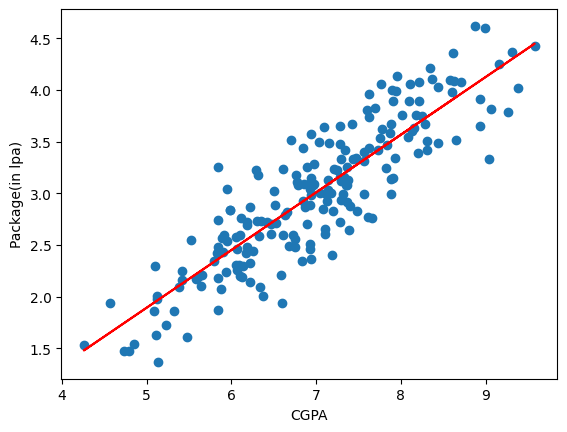

In [17]:
plt.scatter(df['cgpa'],df['package'])
plt.plot(X_train,lr.predict(X_train),color='red')
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [18]:
m = lr.coef_

In [19]:
b = lr.intercept_

In [20]:
# y = mx + b

m * 8.58 + b

array([3.89111601])

MSE, MAE & RMSE | R2 Score & Adjusted R2 Score

In [21]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [22]:
y_pred = lr.predict(X_test)
y_pred

array([3.89111601, 3.09324469, 2.38464568, 2.57434935, 1.6537286 ,
       1.77647803, 2.07219258, 2.93143862, 3.76278706, 2.93701814,
       4.09197872, 3.51170867, 2.97049525, 2.40138424, 3.18809652,
       3.46707251, 1.94386362, 3.24389172, 2.97607477, 3.41685683,
       2.55761079, 3.16577844, 2.85890486, 3.12114229, 3.68467378,
       2.8700639 , 3.49497011, 3.34432308, 3.91901361, 1.96060218,
       3.65119666, 3.2104146 , 3.74046898, 2.7863711 , 2.78079158,
       3.27178932, 3.52844723, 2.61340599, 2.65804215, 2.71383735])

In [23]:
y_test.values

array([4.1 , 3.49, 2.08, 2.33, 1.94, 1.48, 1.86, 3.09, 4.21, 2.87, 3.65,
       4.  , 2.89, 2.6 , 2.99, 3.25, 1.86, 3.67, 2.37, 3.42, 2.48, 3.65,
       2.6 , 2.83, 4.08, 2.56, 3.58, 3.81, 4.09, 2.01, 3.63, 2.92, 3.51,
       1.94, 2.21, 3.34, 3.34, 3.23, 2.01, 2.61])

In [24]:
print("MAE",mean_absolute_error(y_test,y_pred))

MAE 0.2884710931878175


In [25]:
print("MSE",mean_squared_error(y_test,y_pred))

MSE 0.12129235313495527


In [26]:
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))

RMSE 0.34827051717731616


In [27]:
print("MSE",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

MSE 0.780730147510384


In [28]:
# Adjusted R2 score
X_test.shape

(40, 1)

In [29]:
1 - ((1-r2)*(40-1)/(40-1-1))

0.7749598882343415

In [30]:
new_df1 = df.copy()
new_df1['random_feature'] = np.random.random(200)

new_df1 = new_df1[['cgpa','random_feature','package']]
new_df1.head()

,cgpa,random_feature,package
0,6.89,0.512308,3.26
1,5.12,0.388762,1.98
2,7.82,0.277273,3.25
3,7.42,0.107234,3.67
4,6.94,0.869096,3.57


Text(0, 0.5, 'Package(in lpa)')

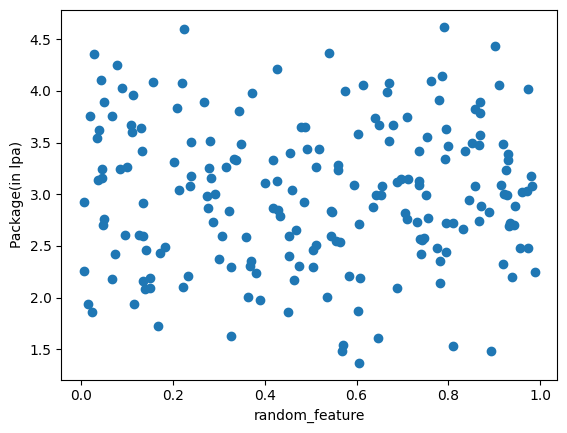

In [31]:
plt.scatter(new_df1['random_feature'],new_df1['package'])
plt.xlabel('random_feature')
plt.ylabel('Package(in lpa)')

In [32]:
X = new_df1.iloc[:,0:2]
y = new_df1.iloc[:,-1]

In [33]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [34]:
lr = LinearRegression()

In [35]:
lr.fit(X_train,y_train)

LinearRegression()

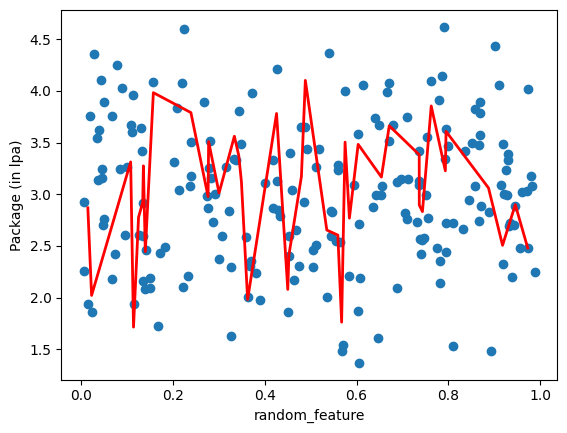

In [43]:
plt.scatter(new_df1['random_feature'], new_df1['package'], label='Data Points')

sort_idx = np.argsort(X_test['random_feature'])
plt.plot(X_test['random_feature'].iloc[sort_idx], y_pred[sort_idx], color='red', linewidth=2, label='Regression Line')

plt.xlabel('random_feature')
plt.ylabel('Package (in lpa)')
plt.show()

In [36]:
y_pred = lr.predict(X_test)

In [37]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.7721058613275735


In [44]:
1 - ((1-r2)*(40-1)/(40-1-2))

0.759787259237172

In [45]:
new_df2 = df.copy()

new_df2['iq'] = new_df2['package'] + (np.random.randint(-12,12,200)/10)

new_df2 = new_df2[['cgpa','iq','package']]

In [46]:
new_df2.sample(5)

,cgpa,iq,package
155,6.98,2.99,3.09
168,8.65,3.22,3.52
50,9.58,5.43,4.43
122,5.12,1.11,2.01
163,8.93,3.01,3.91


Text(0, 0.5, 'Package(in lpa)')

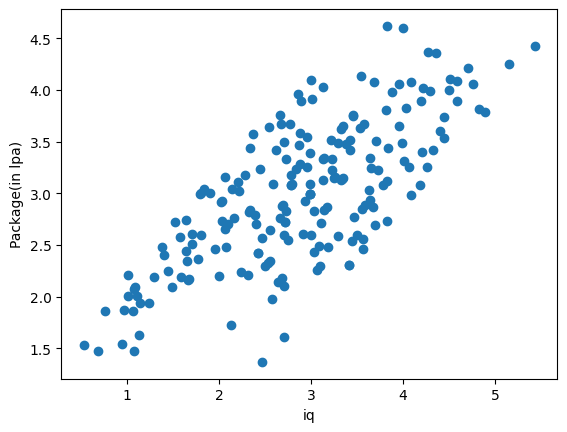

In [47]:
plt.scatter(new_df2['iq'],new_df2['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [48]:
np.random.randint(-100,100)

54

In [49]:
X = new_df2.iloc[:,0:2]
y = new_df2.iloc[:,-1]

In [50]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [51]:
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [52]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.8551318918025552


In [53]:
1 - ((1-r2)*(40-1)/(40-1-2))

0.847301183251342